In [3]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))

from src import configs
import pandas as pd

df = pd.read_csv(configs.RAW_CSV)


In [4]:
df.head()

,Customer_ID,Age,Gender,Annual_Income,Total_Spend,Years_as_Customer,Num_of_Purchases,Average_Transaction_Amount,Num_of_Returns,Num_of_Support_Contacts,Satisfaction_Score,Last_Purchase_Days_Ago,Email_Opt_In,Promotion_Response,Target_Churn
0,1,62,Other,45.15,5892.58,5,22,453.80,2,0,3,129,True,Responded,True
1,2,65,Male,79.51,9025.47,13,77,22.90,2,2,3,227,False,Responded,False
2,3,18,Male,29.19,618.83,13,71,50.53,5,2,2,283,False,Responded,True
3,4,21,Other,79.63,9110.30,3,33,411.83,5,3,5,226,True,Ignored,True
4,5,21,Other,77.66,5390.88,15,43,101.19,3,0,5,242,False,Unsubscribed,False


In [5]:
df.shape

(1000, 15)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Customer_ID                 1000 non-null   int64  
 1   Age                         1000 non-null   int64  
 2   Gender                      1000 non-null   str    
 3   Annual_Income               1000 non-null   float64
 4   Total_Spend                 1000 non-null   float64
 5   Years_as_Customer           1000 non-null   int64  
 6   Num_of_Purchases            1000 non-null   int64  
 7   Average_Transaction_Amount  1000 non-null   float64
 8   Num_of_Returns              1000 non-null   int64  
 9   Num_of_Support_Contacts     1000 non-null   int64  
 10  Satisfaction_Score          1000 non-null   int64  
 11  Last_Purchase_Days_Ago      1000 non-null   int64  
 12  Email_Opt_In                1000 non-null   bool   
 13  Promotion_Response          1000 non-null   s

Ensuring that customer_id, is unique.

In [7]:
df["Customer_ID"].nunique()

1000

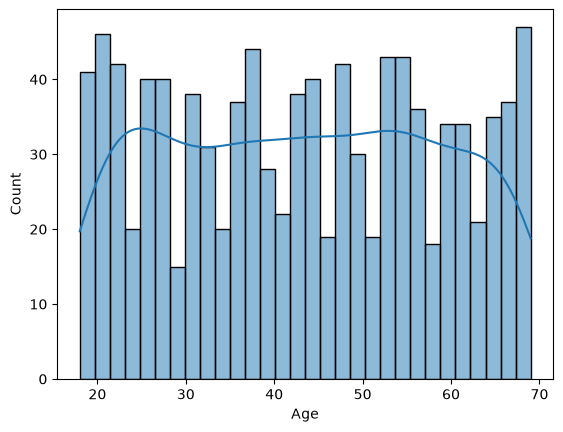

In [8]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x=df["Age"], bins=30, kde=True)
plt.show()


Checking the Categorical Values of email_opt_in and promotion_reponse

In [9]:
print(df["Email_Opt_In"].unique())
print(df["Promotion_Response"].unique())

[ True False]
<ArrowStringArray>
['Responded', 'Ignored', 'Unsubscribed']
Length: 3, dtype: str


Converting Column names to lower_case.

In [10]:
df.columns = df.columns.str.lower()

"return_rate",              # num_of_returns / num_of_purchases
"purchases_per_year",       # num_of_purchases / years_as_customer
"spend_per_year",           # total_spend / years_as_customer
"support_contact_rate",     # num_of_support_contacts / num_of_purchases
"rescency_ratio",           # last_purchase_days_ago / (365 / purchases_per_year)
"spend_to_income_ratio"     # total_spend / annual_income

Looking for null or zeroes in num_of_purchases

In [11]:
df[df['num_of_purchases'] == 0]
df["return_rate"] = df["num_of_returns"] / df["num_of_purchases"]

Looking for null or zeroes in  years_as_customers

In [12]:
df[df["years_as_customer"] == 0]

,customer_id,age,gender,annual_income,total_spend,years_as_customer,num_of_purchases,average_transaction_amount,num_of_returns,num_of_support_contacts,satisfaction_score,last_purchase_days_ago,email_opt_in,promotion_response,target_churn,return_rate


In [13]:
df["purchases_per_year"] = df["num_of_purchases"] / df["years_as_customer"]

Looking for nulls and zeros in annual_income

In [14]:
df["spend_per_year"] = df["total_spend"] / df["years_as_customer"]

In [15]:
df["support_contact_rate"] = df["num_of_support_contacts"] / df["num_of_purchases"]

In [16]:
df["rescency_ratio"] = df["last_purchase_days_ago"] / (365 / df["purchases_per_year"])

In [17]:
df["spend_to_income_ratio"]  =   df["total_spend"] / df["annual_income"]

In [18]:
print(df["spend_per_year"].describe())

count    1000.000000
mean      980.314018
std      1453.644188
min         9.903636
25%       272.962500
50%       525.014375
75%      1016.490486
max      9999.490000
Name: spend_per_year, dtype: float64


In [19]:
churn_rate = df["target_churn"].mean()   # base rate = average p across customers

for p in [churn_rate, 0.3, 0.5, 0.8]:
    share = (p * df["spend_per_year"] > 222).mean()
    print(f"p={p:.2f}  ->  {share:.0%} of customers qualify")

p=0.53  ->  61% of customers qualify
p=0.30  ->  35% of customers qualify
p=0.50  ->  58% of customers qualify
p=0.80  ->  75% of customers qualify


In [23]:
import numpy as np
ratio = df["total_spend"] / (df["average_transaction_amount"] * df["num_of_purchases"].replace(0, np.nan))
print(ratio.describe())
print(ratio.quantile([.05, .25, .5, .75, .95]))

count    1000.000000
mean        1.905835
std         7.349029
min         0.004872
25%         0.197791
50%         0.468212
75%         1.340075
max       151.701690
dtype: float64
0.05    0.042926
0.25    0.197791
0.50    0.468212
0.75    1.340075
0.95    6.211640
dtype: float64
